Web Scraping

In [1]:
import requests
import pandas as pd
import re
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin
from datetime import datetime

In [2]:
# Starting URL
url = "https://books.toscrape.com/"

# Store all products here
all_products = []

# Track pages
page_number = 1

while url:
    print(f"Scraping page {page_number}: {url}")

    response = requests.get(
        url,
        timeout=20,
        headers={"User-Agent": "Mozilla/5.0"}
    )
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    # Extract products from the current page
    for product in soup.select("article.product_pod"):

        name = product.h3.a.get("title", "").strip()

        price_text = product.select_one(".price_color").get_text(
            strip=True
        )

        # Remove currency symbols and unwanted characters
        price = float(re.sub(r"[^0-9.]", "", price_text))

        rating_classes = product.select_one(".star-rating").get("class", [])
        rating_word = next(
            (word for word in rating_classes
             if word in ["One", "Two", "Three", "Four", "Five"]),
            None
        )

        rating_map = {
            "One": 1,
            "Two": 2,
            "Three": 3,
            "Four": 4,
            "Five": 5
        }

        availability = product.select_one(".availability").get_text(
            " ", strip=True
        )

        product_url = urljoin(
            url,
            product.h3.a.get("href", "")
        )

        all_products.append({
            "product_name": name,
            "price_gbp": price,
            "rating": rating_map.get(rating_word),
            "availability": availability,
            "category": "Books",
            "product_url": product_url,
            "scraped_at": datetime.now().isoformat(timespec="seconds")
        })

    # Find the next page
    next_page = soup.select_one("li.next a")

    if next_page:
        url = urljoin(url, next_page.get("href"))
        page_number += 1
        time.sleep(0.2)  # Small delay between requests
    else:
        url = None

# Create the complete dataset
df = pd.DataFrame(all_products)

# Remove duplicate product URLs, if any
df = df.drop_duplicates(subset="product_url")

# Save the dataset
df.to_csv("ecommerce_products_full.csv", index=False)

print("\nScraping completed!")
print("Total pages visited:", page_number)
print("Total unique products:", len(df))
print("Dataset shape:", df.shape)

df.head()

Scraping page 1: https://books.toscrape.com/
Scraping page 2: https://books.toscrape.com/catalogue/page-2.html
Scraping page 3: https://books.toscrape.com/catalogue/page-3.html
Scraping page 4: https://books.toscrape.com/catalogue/page-4.html
Scraping page 5: https://books.toscrape.com/catalogue/page-5.html
Scraping page 6: https://books.toscrape.com/catalogue/page-6.html
Scraping page 7: https://books.toscrape.com/catalogue/page-7.html
Scraping page 8: https://books.toscrape.com/catalogue/page-8.html
Scraping page 9: https://books.toscrape.com/catalogue/page-9.html
Scraping page 10: https://books.toscrape.com/catalogue/page-10.html
Scraping page 11: https://books.toscrape.com/catalogue/page-11.html
Scraping page 12: https://books.toscrape.com/catalogue/page-12.html
Scraping page 13: https://books.toscrape.com/catalogue/page-13.html
Scraping page 14: https://books.toscrape.com/catalogue/page-14.html
Scraping page 15: https://books.toscrape.com/catalogue/page-15.html
Scraping page 16: h

,product_name,price_gbp,rating,availability,category,product_url,scraped_at
0,A Light in the Attic,51.77,3,In stock,Books,https://books.toscrape.com/catalogue/a-light-i...,2026-11-23T22:09:42
1,Tipping the Velvet,53.74,1,In stock,Books,https://books.toscrape.com/catalogue/tipping-t...,2026-11-23T22:09:42
2,Soumission,50.10,1,In stock,Books,https://books.toscrape.com/catalogue/soumissio...,2026-11-23T22:09:42
3,Sharp Objects,47.82,4,In stock,Books,https://books.toscrape.com/catalogue/sharp-obj...,2026-11-23T22:09:42
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,Books,https://books.toscrape.com/catalogue/sapiens-a...,2026-11-23T22:09:42


In [3]:
print("Rows and columns:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate product URLs:")
print(df["product_url"].duplicated().sum())

print("\nPrice summary:")
print(df["price_gbp"].describe())

print("\nRating counts:")
print(df["rating"].value_counts().sort_index())

Rows and columns: (1000, 7)

Missing values:
product_name    0
price_gbp       0
rating          0
availability    0
category        0
product_url     0
scraped_at      0
dtype: int64

Duplicate product URLs:
0

Price summary:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64

Rating counts:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


In [4]:
import os
print(os.getcwd())

C:\Users\satya\Downloads


Validate scraped dataset

In [5]:
print("Total products:", len(df))
print("Total columns:", len(df.columns))
print("Column names:", df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nData types:")
print(df.dtypes)

Total products: 1000
Total columns: 7
Column names: ['product_name', 'price_gbp', 'rating', 'availability', 'category', 'product_url', 'scraped_at']

First 5 records:


,product_name,price_gbp,rating,availability,category,product_url,scraped_at
0,A Light in the Attic,51.77,3,In stock,Books,https://books.toscrape.com/catalogue/a-light-i...,2026-11-23T22:09:42
1,Tipping the Velvet,53.74,1,In stock,Books,https://books.toscrape.com/catalogue/tipping-t...,2026-11-23T22:09:42
2,Soumission,50.10,1,In stock,Books,https://books.toscrape.com/catalogue/soumissio...,2026-11-23T22:09:42
3,Sharp Objects,47.82,4,In stock,Books,https://books.toscrape.com/catalogue/sharp-obj...,2026-11-23T22:09:42
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,Books,https://books.toscrape.com/catalogue/sapiens-a...,2026-11-23T22:09:42



Last 5 records:


,product_name,price_gbp,rating,availability,category,product_url,scraped_at
995,Alice in Wonderland (Alice's Adventures in Won...,55.53,1,In stock,Books,https://books.toscrape.com/catalogue/alice-in-...,2026-11-23T22:11:52
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",57.06,4,In stock,Books,https://books.toscrape.com/catalogue/ajin-demi...,2026-11-23T22:11:52
997,A Spy's Devotion (The Regency Spies of London #1),16.97,5,In stock,Books,https://books.toscrape.com/catalogue/a-spys-de...,2026-11-23T22:11:52
998,1st to Die (Women's Murder Club #1),53.98,1,In stock,Books,https://books.toscrape.com/catalogue/1st-to-di...,2026-11-23T22:11:52
999,"1,000 Places to See Before You Die",26.08,5,In stock,Books,https://books.toscrape.com/catalogue/1000-plac...,2026-11-23T22:11:52



Data types:
product_name        str
price_gbp       float64
rating            int64
availability        str
category            str
product_url         str
scraped_at          str
dtype: object


Data cleaning

In [6]:
# Check missing values

print(df.isnull().sum())

product_name    0
price_gbp       0
rating          0
availability    0
category        0
product_url     0
scraped_at      0
dtype: int64


In [7]:
# Check duplicates

print("Duplicate URLs:", df["product_url"].duplicated().sum())
print("Duplicate product names:", df["product_name"].duplicated().sum())

Duplicate URLs: 0
Duplicate product names: 1


In [8]:
# Standardize the data

df["product_name"] = df["product_name"].str.strip()

df["price_gbp"] = pd.to_numeric(
    df["price_gbp"], errors="coerce"
)

df["rating"] = pd.to_numeric(
df["rating"], errors="coerce"
)

df["scraped_at"] = pd.to_datetime(
    df["scraped_at"], errors="coerce"
)

df["availability"] = (
    df["availability"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print(df.dtypes)

product_name               str
price_gbp              float64
rating                   int64
availability               str
category                   str
product_url                str
scraped_at      datetime64[us]
dtype: object


In [9]:
# Validate price and rating ranges

print("Invalid or missing prices:",
      ((df["price_gbp"] < 0) | df["price_gbp"].isna()).sum())

print("Invalid ratings:",
      (~df["rating"].between(1, 5)).sum())

Invalid or missing prices: 0
Invalid ratings: 0


Exploratory data analysis

In [10]:
# Overall price statistics

print("Average price:", round(df["price_gbp"].mean(), 2))
print("Median price:", round(df["price_gbp"].median(), 2))
print("Minimum price:", df["price_gbp"].min())
print("Maximum price:", df["price_gbp"].max())

Average price: 35.07
Median price: 35.98
Minimum price: 10.0
Maximum price: 59.99


In [11]:
# Most expensive products

df.sort_values(
    by="price_gbp",
    ascending=False
)[["product_name", "price_gbp", "rating"]].head(10)

,product_name,price_gbp,rating
648,The Perfect Play (Play by Play #1),59.99,3
617,Last One Home (New Beginnings #1),59.98,3
860,Civilization and Its Discontents,59.95,2
560,The Barefoot Contessa Cookbook,59.92,5
366,The Diary of a Young Girl,59.90,3
657,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,3
133,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,1
387,Boar Island (Anna Pigeon #19),59.48,3
549,The Man Who Mistook His Wife for a Hat and Oth...,59.45,4
393,The Improbability of Love,59.45,1


In [12]:
# Average price by rating

rating_analysis = (
    df.groupby("rating")["price_gbp"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(rating_analysis)

,count,mean,median,min,max
rating,,,,,
1,226,34.56,34.77,10.40,59.64
2,196,34.81,36.22,10.02,59.95
3,203,34.69,33.78,10.16,59.99
4,179,36.09,37.80,10.01,59.45
5,196,35.37,36.90,10.00,59.92


Data visualizations

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

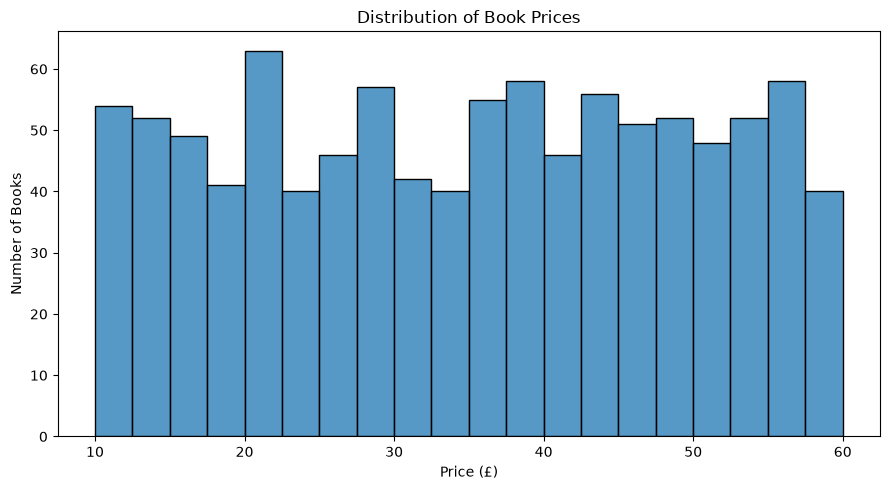

In [14]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="price_gbp", bins=20)
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

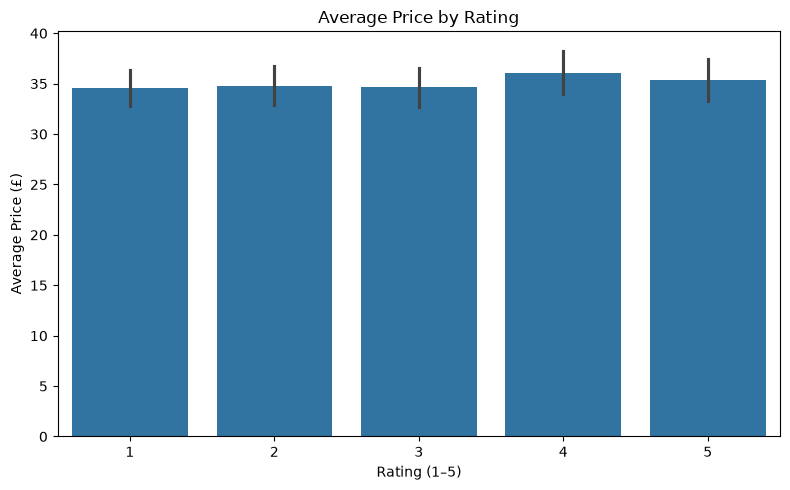

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="rating", y="price_gbp")
plt.title("Average Price by Rating")
plt.xlabel("Rating (1–5)")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()

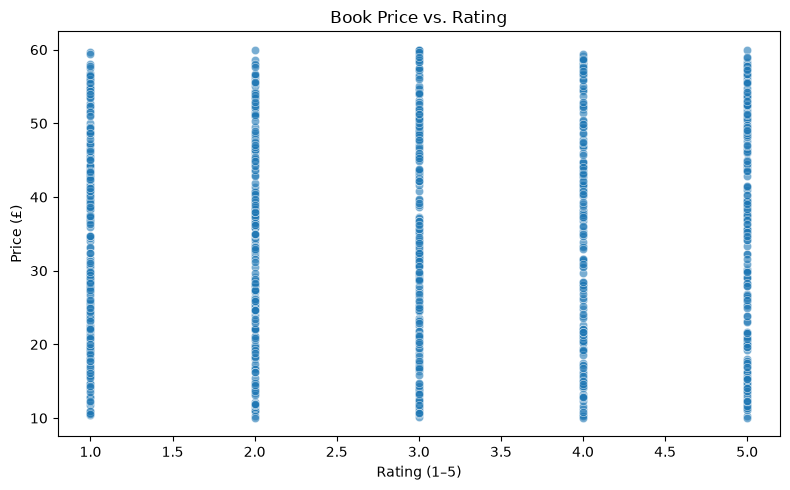

In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="rating", y="price_gbp", alpha=0.6
)
plt.title("Book Price vs. Rating")
plt.xlabel("Rating (1–5)")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

Save the cleaned dataset

In [17]:
df.to_csv("ecommerce_products_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


SQLite and SQL analysis.

In [18]:
# Store scraped data in SQLite

import sqlite3

In [19]:
# Connect to SQLite

conn = sqlite3.connect("ecommerce_analysis.db")

print("Database connected successfully!")

Database connected successfully!


In [20]:
# Save DataFrame into a SQL table

df.to_sql(
    "products",
    conn,
    if_exists="replace",
    index=False
)

print("Data successfully saved to SQLite!")

Data successfully saved to SQLite!


In [21]:
# Check database tables

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    """,
    conn
)

display(tables)

,name
0,products


In [22]:
# Run first SQL query

query = """
SELECT *
FROM products
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

display(result)

,product_name,price_gbp,rating,availability,category,product_url,scraped_at
0,A Light in the Attic,51.77,3,In stock,Books,https://books.toscrape.com/catalogue/a-light-i...,2026-11-23 22:09:42
1,Tipping the Velvet,53.74,1,In stock,Books,https://books.toscrape.com/catalogue/tipping-t...,2026-11-23 22:09:42
2,Soumission,50.10,1,In stock,Books,https://books.toscrape.com/catalogue/soumissio...,2026-11-23 22:09:42
3,Sharp Objects,47.82,4,In stock,Books,https://books.toscrape.com/catalogue/sharp-obj...,2026-11-23 22:09:42
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,Books,https://books.toscrape.com/catalogue/sapiens-a...,2026-11-23 22:09:42
5,The Requiem Red,22.65,1,In stock,Books,https://books.toscrape.com/catalogue/the-requi...,2026-11-23 22:09:42
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,Books,https://books.toscrape.com/catalogue/the-dirty...,2026-11-23 22:09:42
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,Books,https://books.toscrape.com/catalogue/the-comin...,2026-11-23 22:09:42
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,Books,https://books.toscrape.com/catalogue/the-boys-...,2026-11-23 22:09:42
9,The Black Maria,52.15,1,In stock,Books,https://books.toscrape.com/catalogue/the-black...,2026-11-23 22:09:42


Practice real Data Analyst SQL queries

In [23]:
# Count all products

pd.read_sql_query("""
SELECT COUNT(*) AS total_products
FROM products;
""", conn)

,total_products
0,1000


In [24]:
# Find the most expensive products

pd.read_sql_query("""
SELECT product_name, price_gbp, rating
FROM products
ORDER BY price_gbp DESC
LIMIT 10;
""", conn)

,product_name,price_gbp,rating
0,The Perfect Play (Play by Play #1),59.99,3
1,Last One Home (New Beginnings #1),59.98,3
2,Civilization and Its Discontents,59.95,2
3,The Barefoot Contessa Cookbook,59.92,5
4,The Diary of a Young Girl,59.90,3
5,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,3
6,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,1
7,Boar Island (Anna Pigeon #19),59.48,3
8,The Improbability of Love,59.45,1
9,The Man Who Mistook His Wife for a Hat and Oth...,59.45,4


In [25]:
# Calculate price statistics

pd.read_sql_query("""
SELECT
    ROUND(AVG(price_gbp), 2) AS average_price,
    ROUND(MIN(price_gbp), 2) AS minimum_price,
    ROUND(MAX(price_gbp), 2) AS maximum_price
FROM products;
""", conn)

,average_price,minimum_price,maximum_price
0,35.07,10.0,59.99


In [26]:
# Analyze products by rating

pd.read_sql_query("""
SELECT
    rating,
    COUNT(*) AS product_count,
    ROUND(AVG(price_gbp), 2) AS average_price
FROM products
GROUP BY rating
ORDER BY rating;
""", conn)

,rating,product_count,average_price
0,1,226,34.56
1,2,196,34.81
2,3,203,34.69
3,4,179,36.09
4,5,196,35.37


In [27]:
# Find products above the average price

pd.read_sql_query("""
SELECT product_name, price_gbp, rating
FROM products
WHERE price_gbp > (
    SELECT AVG(price_gbp)
    FROM products
)
ORDER BY price_gbp DESC;
""", conn)

,product_name,price_gbp,rating
0,The Perfect Play (Play by Play #1),59.99,3
1,Last One Home (New Beginnings #1),59.98,3
2,Civilization and Its Discontents,59.95,2
3,The Barefoot Contessa Cookbook,59.92,5
4,The Diary of a Young Girl,59.90,3
...,...,...,...
508,Doing It Over (Most Likely To #1),35.61,3
509,"So Cute It Hurts!!, Vol. 6 (So Cute It Hurts!!...",35.43,4
510,The Darkest Lie,35.35,5
511,Most Wanted,35.28,3


In [28]:
# Analyze availability

pd.read_sql_query("""
SELECT
    availability,
    COUNT(*) AS product_count
FROM products
GROUP BY availability;
""", conn)

,availability,product_count
0,In stock,1000


In [29]:
# Find the top-rated books

pd.read_sql_query("""
SELECT product_name, price_gbp, availability
FROM products
WHERE rating = 5
ORDER BY price_gbp DESC;
""", conn)

,product_name,price_gbp,availability
0,The Barefoot Contessa Cookbook,59.92,In stock
1,Life Without a Recipe,59.04,In stock
2,Approval Junkie: Adventures in Caring Too Much,58.81,In stock
3,How to Speak Golf: An Illustrated Guide to Lin...,58.32,In stock
4,Digital Fortress,58.00,In stock
...,...,...,...
191,The Darkest Corners,11.33,In stock
192,Dear Mr. Knightley,11.21,In stock
193,The Power Greens Cookbook: 140 Delicious Super...,11.05,In stock
194,Greek Mythic History,10.23,In stock


In [30]:
# Check for duplicate product URLs

pd.read_sql_query("""
SELECT
    product_url,
    COUNT(*) AS occurrences
FROM products
GROUP BY product_url
HAVING COUNT(*) > 1;
""", conn)

,product_url,occurrences


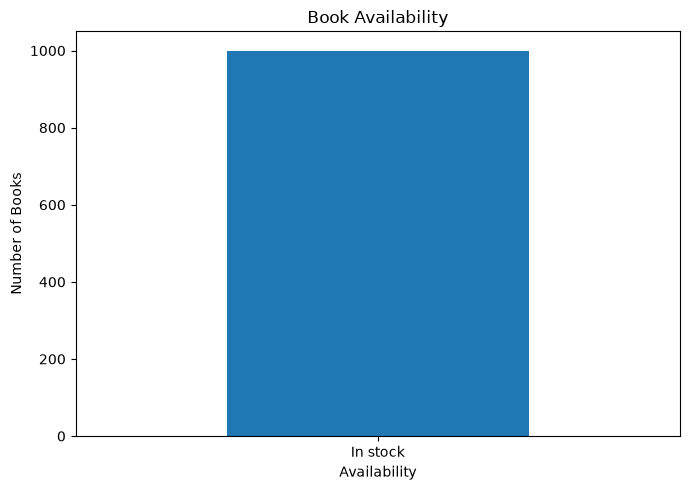

In [31]:
# Data Visualization
# Product availability

availability_counts = (
    df["availability"]
    .str.contains("In stock", case=False, na=False)
    .map({True: "In stock", False: "Out of stock"})
    .value_counts()
)

availability_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Book Availability")
plt.xlabel("Availability")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [32]:
print("TOTAL PRODUCTS:", len(df))
print("UNIQUE PRODUCT URLs:", df["product_url"].nunique())

print("\nPRICE STATISTICS:")
print(df["price_gbp"].describe())

print("\nMEDIAN PRICE:")
print(df["price_gbp"].median())

print("\nRATING COUNTS:")
print(df["rating"].value_counts().sort_index())

print("\nAVAILABILITY COUNTS:")
print(df["availability"].value_counts())

print("\nAVERAGE PRICE BY RATING:")
print(df.groupby("rating")["price_gbp"].mean().round(2))


TOTAL PRODUCTS: 1000
UNIQUE PRODUCT URLs: 1000

PRICE STATISTICS:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64

MEDIAN PRICE:
35.980000000000004

RATING COUNTS:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

AVAILABILITY COUNTS:
availability
In stock    1000
Name: count, dtype: int64

AVERAGE PRICE BY RATING:
rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price_gbp, dtype: float64


In [33]:
# Save the cleaned dataset

df.to_csv("ecommerce_products_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
